In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import anndata as ad
import scanpy as sc

adata = sc.read_h5ad('../data/tissdiss_object_with_ranks.h5ad')

FIGURES_DIR = '../figures'
os.makedirs(FIGURES_DIR, exist_ok=True)

In [2]:
def save_fig(fig, stem, subdir=''):
    output_dir = os.path.join(FIGURES_DIR, subdir)
    os.makedirs(output_dir, exist_ok=True)
    for ax in fig.axes:
        for coll in ax.collections:
            coll.set_rasterized(True)
    for ext in ['png', 'pdf']:
        fig.savefig(os.path.join(output_dir, f'{stem}.{ext}'), dpi=150, bbox_inches='tight')
    plt.close(fig)

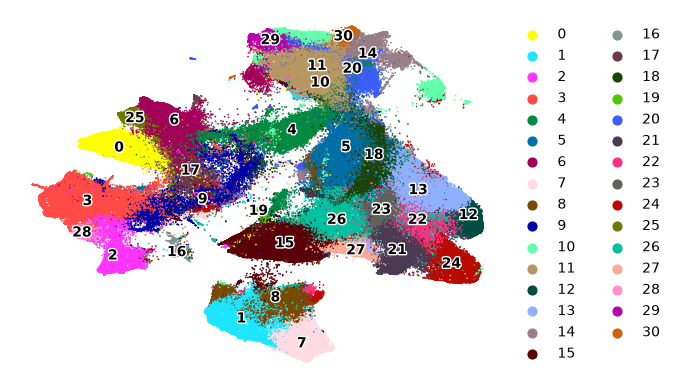

In [3]:
fig = sc.pl.embedding(adata, basis='X_umap_harmony', color='leiden_harmony', legend_loc='on data', legend_fontoutline=2,
                      show=False, return_fig=True, size=6, title='', frameon=False)

ax = fig.axes[0]
clusters = adata.obs['leiden_harmony'].cat.categories
cluster_colors = adata.uns['leiden_harmony_colors']
handles = [ax.scatter([], [], color=color, s=40, label=cluster) for cluster, color in zip(clusters, cluster_colors)]
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, ncol=2)
plt.show()

save_fig(fig, stem='tissdiss_leiden_umap')

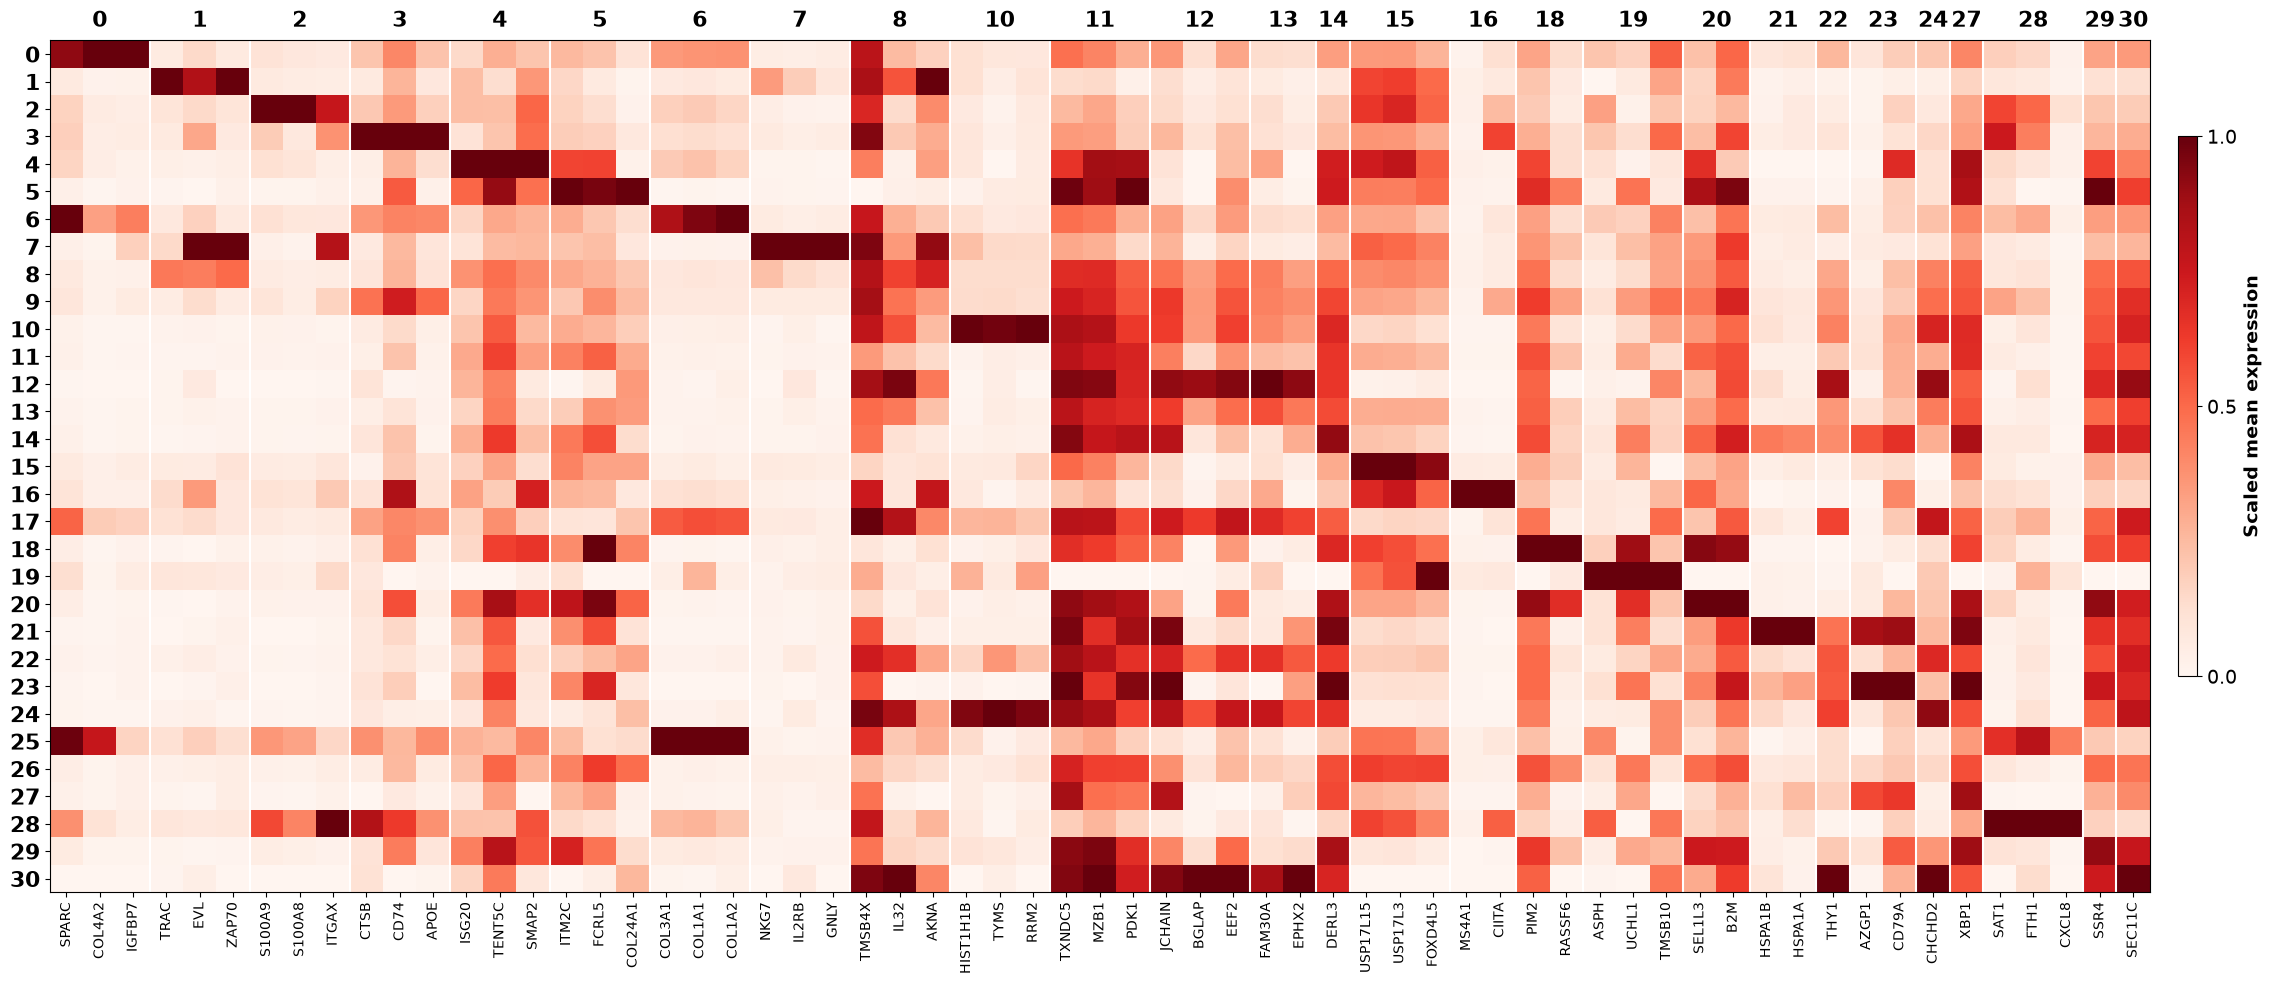

In [8]:
# Heatmap of tissdiss_leiden top DEG's
def grouped_heatmap(mat, groups, vmin=0, vmax=1, cmap="Reds",
                    cbar_label="Scaled mean expression", title="", figsize=(28, 12)):
    fig, ax = plt.subplots(figsize=figsize)
    fig.subplots_adjust(left=0.16, right=0.91, top=0.83, bottom=0.12)

    im = ax.imshow(mat.clip(vmin, vmax).values, cmap=cmap, vmin=vmin, vmax=vmax,
                   aspect="auto", interpolation="nearest")

    ax.set_yticks(range(mat.shape[0]))
    ax.set_yticklabels(mat.index, fontsize=16, fontweight="bold")
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=90)

    start = 0
    for label, genes in groups.items():
        if not genes:
            continue
        end = start + len(genes)
        if start > 0:
            ax.axvline(start - 0.5, color="white", lw=1.5)
        ax.text((start + end - 1) / 2, -0.8, label,
                ha="center", va="bottom", clip_on=False, fontsize=16, fontweight="bold")
        start = end

    for spine in ax.spines.values():
        spine.set_edgecolor("black")

    cax = fig.add_axes([0.92, 0.30, 0.007, 0.45])
    colorbar = fig.colorbar(im, cax=cax, ticks=np.linspace(vmin, vmax, 3))
    colorbar.set_label(cbar_label, fontsize=14, fontweight="bold")
    colorbar.ax.tick_params(labelsize=14)

    if title:
        fig.suptitle(title, y=0.985)
    return fig, ax


ranked_names = pd.DataFrame(adata.uns['ttest_leiden_harmony']['names'])
used_genes = set()
marker_genes = {}
for cluster in ranked_names.columns:
    cluster_genes = [gene for gene in ranked_names[cluster][:3] if gene not in used_genes]
    used_genes.update(cluster_genes)
    marker_genes[cluster] = cluster_genes

gene_order = [gene for genes in marker_genes.values() for gene in genes]
cluster_means = adata[:, gene_order].to_df().groupby(adata.obs['leiden_harmony'], observed=True).mean()
scaled_means = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

fig, ax = grouped_heatmap(scaled_means, marker_genes)
plt.show()

save_fig(fig, stem='tissdiss_leiden_deg_heatmap')